In [53]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy.stats import f

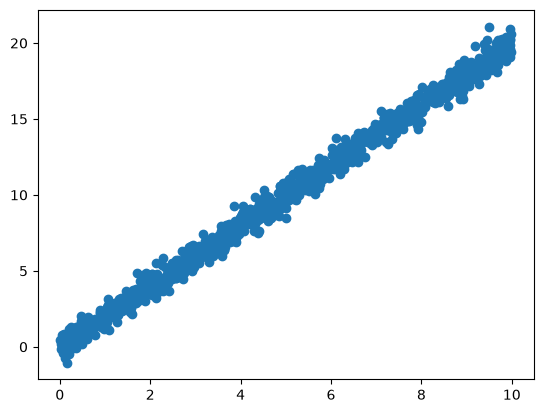

In [17]:
upper = 10
xs = np.random.rand(1000) * upper
ys = 2 * xs + np.random.normal(0, 0.5, size=len(xs))

plt.scatter(xs, ys)

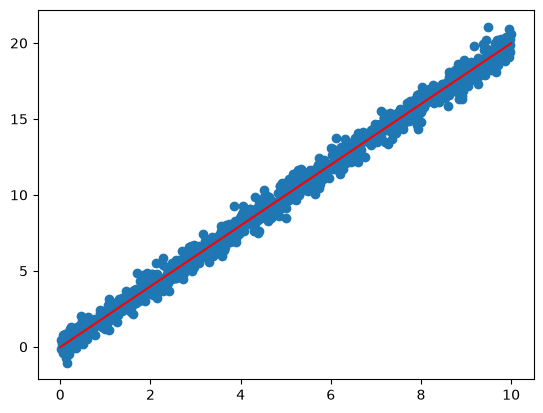

In [ ]:
model = LinearRegression()
model.fit(xs.reshape(-1, 1), ys.reshape(-1, 1))

x_plot = np.linspace(0, 10, 500)
plt.scatter(xs, ys)
plt.plot(x_plot, model.predict(x_plot.reshape(-1, 1)), color='red')

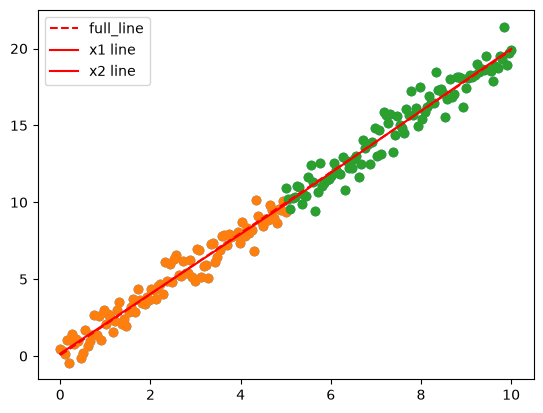

In [77]:
x1 = np.linspace(0, 5, 100).reshape(-1, 1)
x2 = np.linspace(5, 10, 100).reshape(-1, 1)
y1 = 2 * x1 + np.random.normal(0, 0.7, size=x1.shape)
y2 = 2 * x2 + np.random.normal(0, 0.7, size=x2.shape)

x_full = np.concatenate((x1, x2))
y_full = np.concatenate((y1, y2))

model_full = LinearRegression()
model_full.fit(x_full, y_full)

model1 = LinearRegression()
model1.fit(x1, y1)

model2 = LinearRegression()
model2.fit(x2, y2)

x_plot = np.linspace(0, np.max(x_full), 100)
plt.scatter(x_full, y_full)
plt.plot(x_plot, model_full.predict(x_plot.reshape(-1, 1)), color='red', label="full_line", linestyle='--')

x_plot = np.linspace(0, np.max(x1), 100)
plt.scatter(x1, y1)
plt.plot(x_plot, model1.predict(x_plot.reshape(-1, 1)), color='red', label="x1 line")

x_plot = np.linspace(np.max(x1), np.max(x2), 100)
plt.scatter(x2, y2)
plt.plot(x_plot, model2.predict(x_plot.reshape(-1, 1)), color='red', label="x2 line")
plt.legend()


In [76]:
rss1 = np.sum((model1.predict(x1) - y1) ** 2)
rss2 = np.sum((model2.predict(x2) - y2) ** 2)
rssp = np.sum((model_full.predict(x_full) - y_full) ** 2)

k = 2
dof = len(x1) + len(x2) - 2 * k

chow = ((rssp - rss1 - rss2) / k) / ((rss1 + rss2) / dof)
p_value = f.sf(chow, k, dof)
print("Chow statistic:", chow)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Evidence of a structural break.")
else:
    print("Fail to reject H0: Insufficient evidence of a structural break.")

Chow statistic: 0.7451606796919791
p-value: 0.4759978330450392
Fail to reject H0: Insufficient evidence of a structural break.


array([0.00156939])